# Lab 1 – From data to a first classifier: decision trees on *Bank Marketing* – SOLUTION

**Machine Learning** – Master in Data Science and Business Analytics – A.Y. 2026/27
Lab tutor: Francesco Casadei

### Business context
A Portuguese bank runs telephone marketing campaigns to sell a **term deposit**. Every row of the dataset is a contact with a client; the target `y` says whether the client subscribed.

> *Business question*: **before calling**, can we predict which clients are likely to subscribe, so that the call centre focuses its effort on them?

**Dataset**: [Bank Marketing – UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing), file `bank-additional-full.csv` (41,188 contacts, 20 attributes + target). Source: Moro S., Cortez P., Rita P. (2014), *A data-driven approach to predict the success of bank telemarketing*, Decision Support Systems 62: 22–31.

### Goals of the lab
1. explore the data quickly, looking for what matters for modelling
2. prepare the data: hidden missing values, data leakage, encoding of categorical attributes
3. split the data with the **holdout** method and set a **baseline**
4. train, visualise and interpret a **decision tree**
5. observe **overfitting** when the tree grows

Indicative timing: EDA 20' · preparation 25' · holdout and baseline 15' · first tree 30' · overfitting 30'

## 0. Setup
Put `bank-additional-full.csv` in the appropriate folder.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42          # fix the randomness: everybody gets the same results
DATA_PATH = '../../Data/bank-additional-full.csv'
sns.set_theme(style='whitegrid')

## 1. Load the data
Open the raw file with a text viewer (Jupyter, VS Code and Colab can all show it) and check:
- the **separator** character
- whether the first row is a **header**
- how strings are quoted

Then read it with [`pd.read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) into a dataframe called `df` and show its shape and first rows.

In [2]:
df = pd.read_csv(DATA_PATH, sep=';')
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Attributes
| Group | Attributes |
|---|---|
| Client | `age`, `job`, `marital`, `education`, `default` (has credit in default?), `housing` (housing loan?), `loan` (personal loan?) |
| Last contact of the current campaign | `contact` (cellular/telephone), `month`, `day_of_week`, `duration` (duration of the call, in seconds) |
| Campaign history | `campaign` (number of contacts in this campaign), `pdays` (days since the client was last contacted in a previous campaign; `999` = never contacted), `previous` (contacts before this campaign), `poutcome` (outcome of the previous campaign) |
| Socio-economic context | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` (quarterly/monthly indicators) |
| **Target** | `y`: has the client subscribed a term deposit? (`yes`/`no`) |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

**Question**: according to `info()`, are there missing values? Keep the answer in mind for section 2.3.

## 2. Exploratory analysis (compact)
The complete EDA checklist was discussed in session 2: here we focus on what matters for building a classifier.

### 2.1 The target
Show the absolute and relative frequencies of `y` (`value_counts`, option `normalize=True`) and a bar chart (`sns.countplot`).

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.887
yes    0.113
Name: proportion, dtype: float64


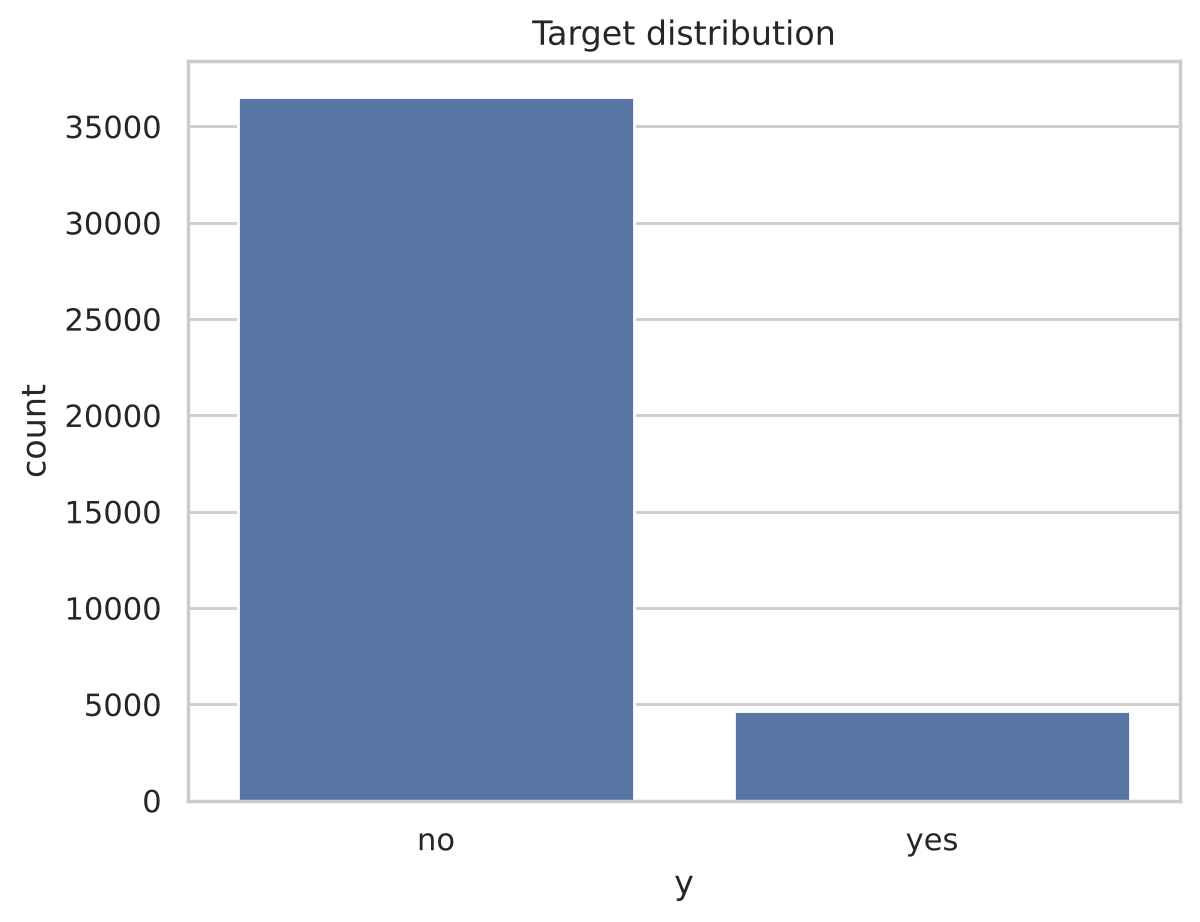

In [4]:
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True).round(3))
sns.countplot(data=df, x='y')
plt.title('Target distribution');

**Question**: a trivial "model" that always answers `no` – what accuracy would it get? Is the dataset balanced?

> **Answer.** About 88.7% of the contacts are `no`: always answering `no` already gives ~0.887 accuracy. The classes are strongly **imbalanced** (≈ 1 `yes` every 8 contacts). Any model must be compared with this **baseline**, and accuracy alone will turn out to be a poor measure (Lab 3).

### 2.2 Numeric attributes
Show a statistical summary of the numeric attributes (`describe`, transposed for readability) and their histograms.

In [5]:
num_cols = df.select_dtypes(include='number').columns.tolist()
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


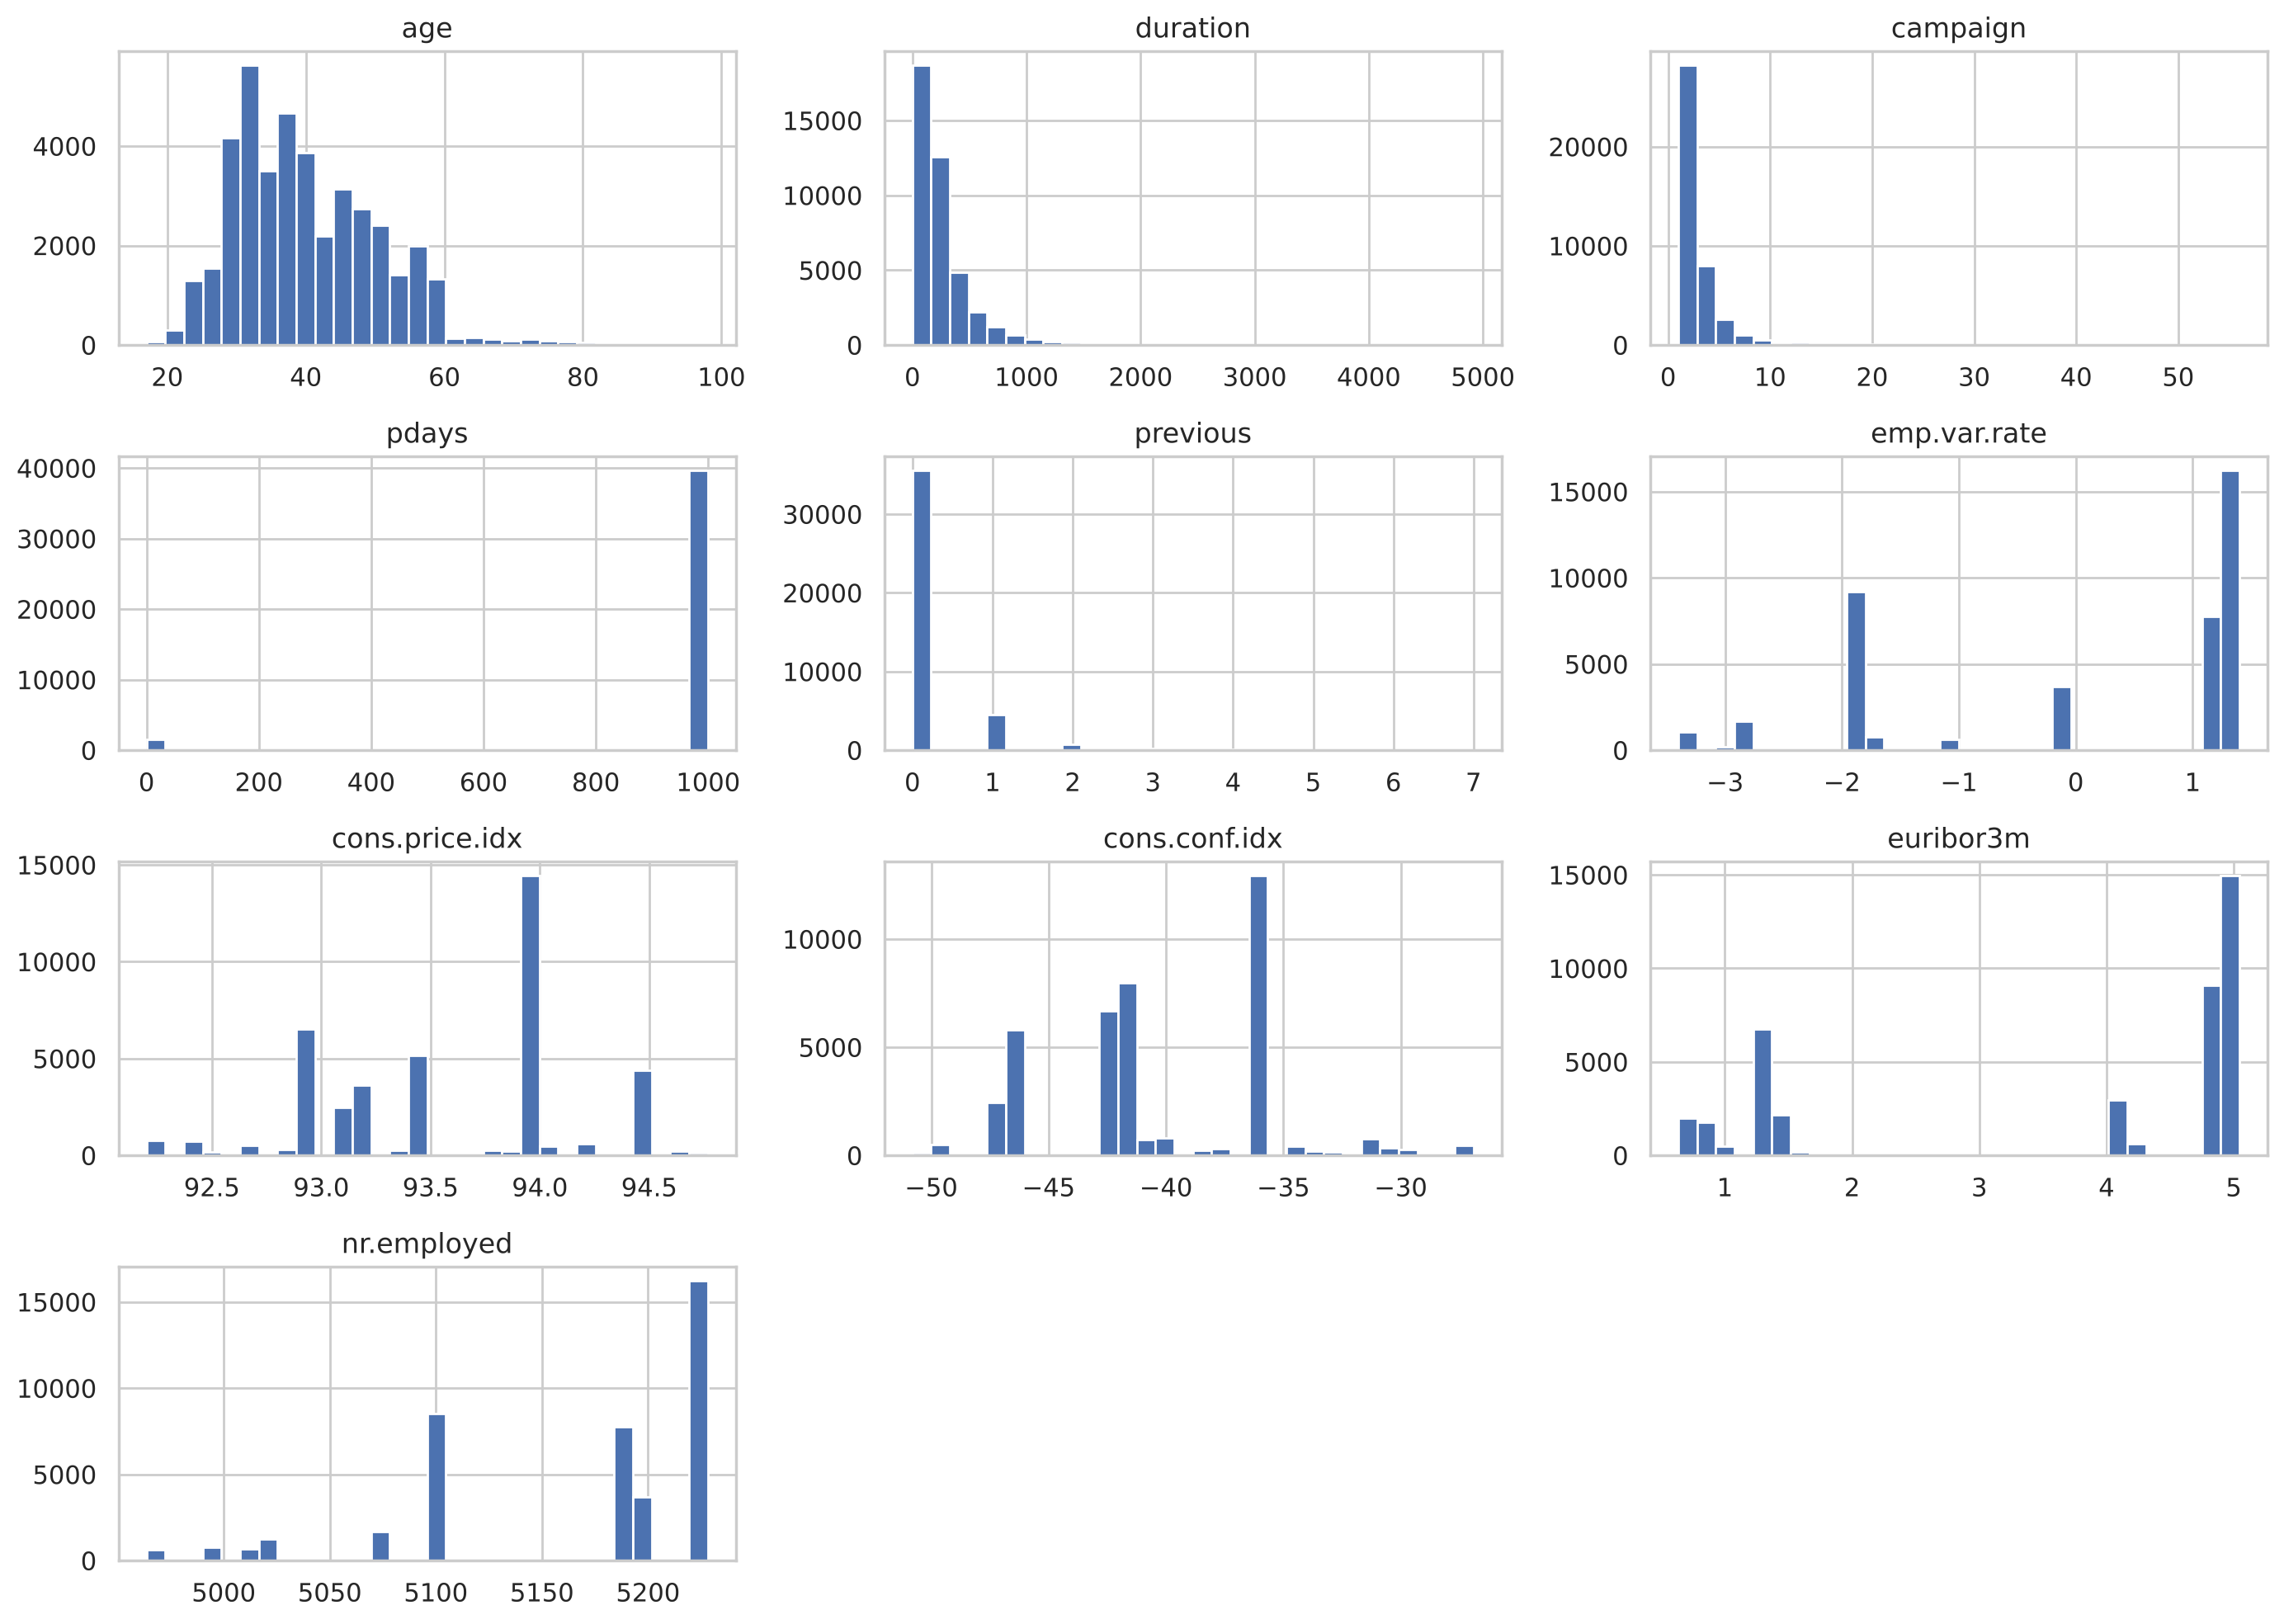

In [6]:
df[num_cols].hist(figsize=(14, 10), bins=30);
plt.tight_layout()

**Questions**
- Look at `pdays`: median, quartiles, maximum. What is happening?
- Which distributions are strongly skewed?
- The socio-economic attributes have very few distinct values: why? (hint: what do they describe?)

> **Answer.** `pdays` is 999 for more than 96% of the rows: 999 is a **code** meaning "never contacted before", not a number of days. `campaign`, `duration` and `previous` are strongly right-skewed. The socio-economic indicators are monthly/quarterly values, identical for all the calls made in the same period: they describe the **moment** of the call, not the client.

### 2.3 Categorical attributes and *hidden* missing values
`info()` reports no missing values, but several categorical attributes contain the string `'unknown'`. Count, for each categorical attribute, how many rows are `'unknown'`.

In [7]:
cat_cols = [c for c in df.columns if c not in num_cols and c != 'y']
print(cat_cols)
(df[cat_cols] == 'unknown').sum().sort_values(ascending=False)

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


default        8597
education      1731
housing         990
loan            990
job             330
marital          80
contact           0
month             0
day_of_week       0
poutcome          0
dtype: int64

In [8]:
df['default'].value_counts()

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

**Question**: what would you do with `'unknown'`? Drop the rows? Replace it with the most frequent value? Keep it as a category of its own? Look at `default` in particular.

> **Answer.** Dropping the rows would lose ~25% of the data (mostly because of `default`). For `default`, `yes` appears only 3 times: the real information is *known `no`* vs *`unknown`* – a client who does not declare it may behave differently. For a decision tree the simplest, and reasonable, choice is to keep `'unknown'` as **a category of its own**: the tree will use it only if it is useful. Imputation techniques are discussed in session 4.

### 2.4 Duplicates

In [9]:
df.duplicated().sum()

np.int64(12)

### 2.5 Attributes vs target
A quick way to see if a categorical attribute is related to the target: the **subscription rate** (fraction of `yes`) for each of its values. The function below draws it; the dashed line is the overall rate.

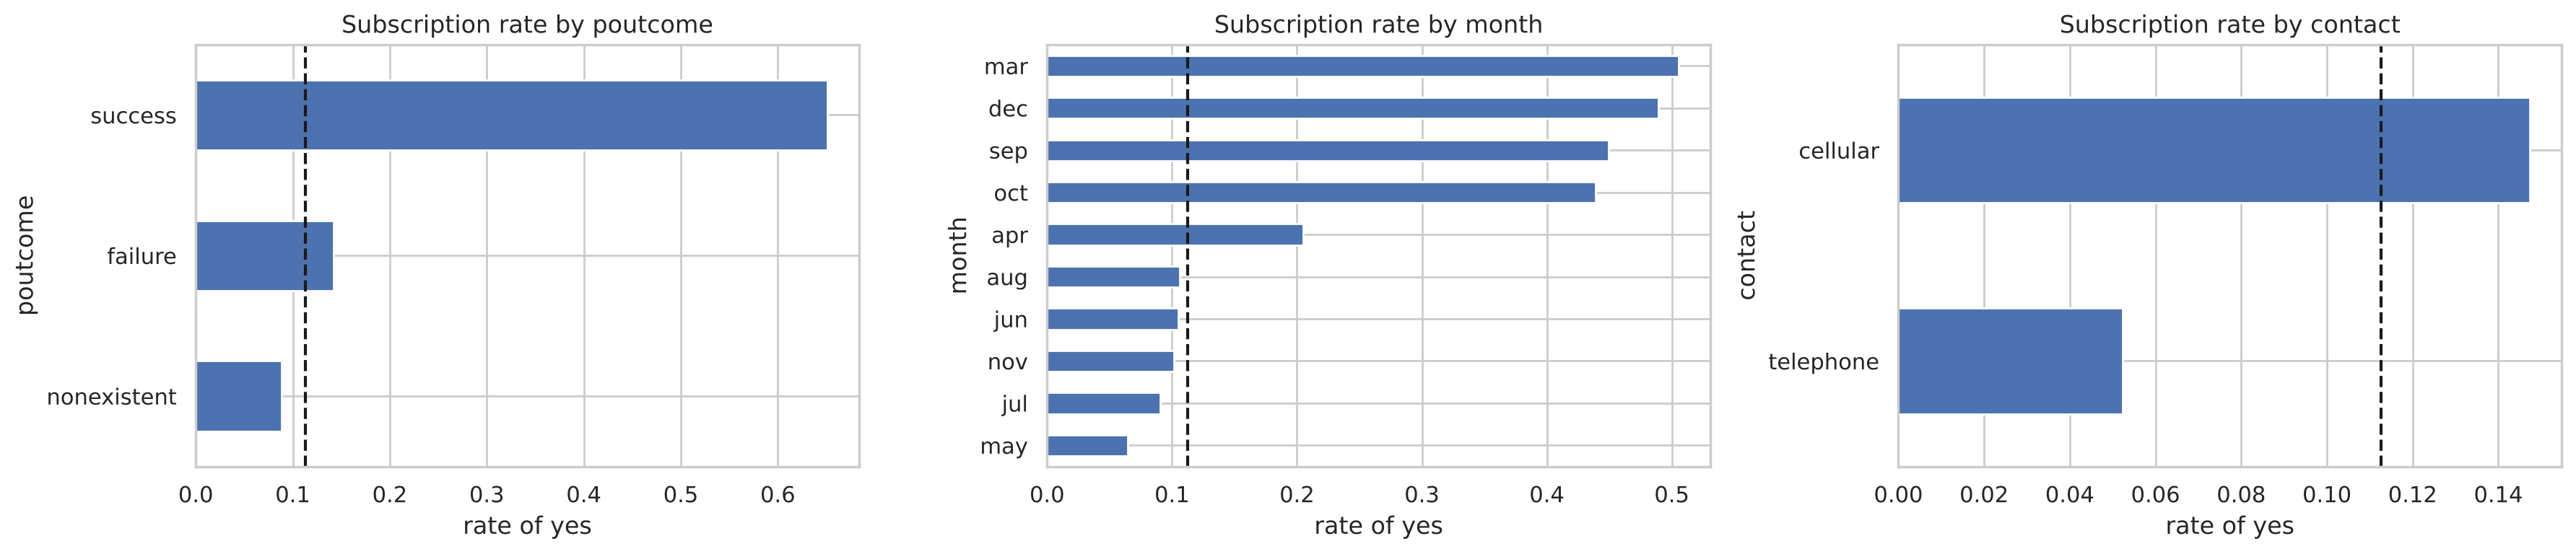

In [10]:
base_rate = (df['y'] == 'yes').mean()

def plot_rate(col, ax):
    rate = (df['y'] == 'yes').groupby(df[col]).mean().sort_values()
    rate.plot.barh(ax=ax)
    ax.axvline(base_rate, ls='--', c='k')
    ax.set_title(f'Subscription rate by {col}')
    ax.set_xlabel('rate of yes')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['poutcome', 'month', 'contact']):
    plot_rate(col, ax)
plt.tight_layout()

For the numeric attributes, compare the distributions for `yes` and `no` with boxplots (`x='y'`).

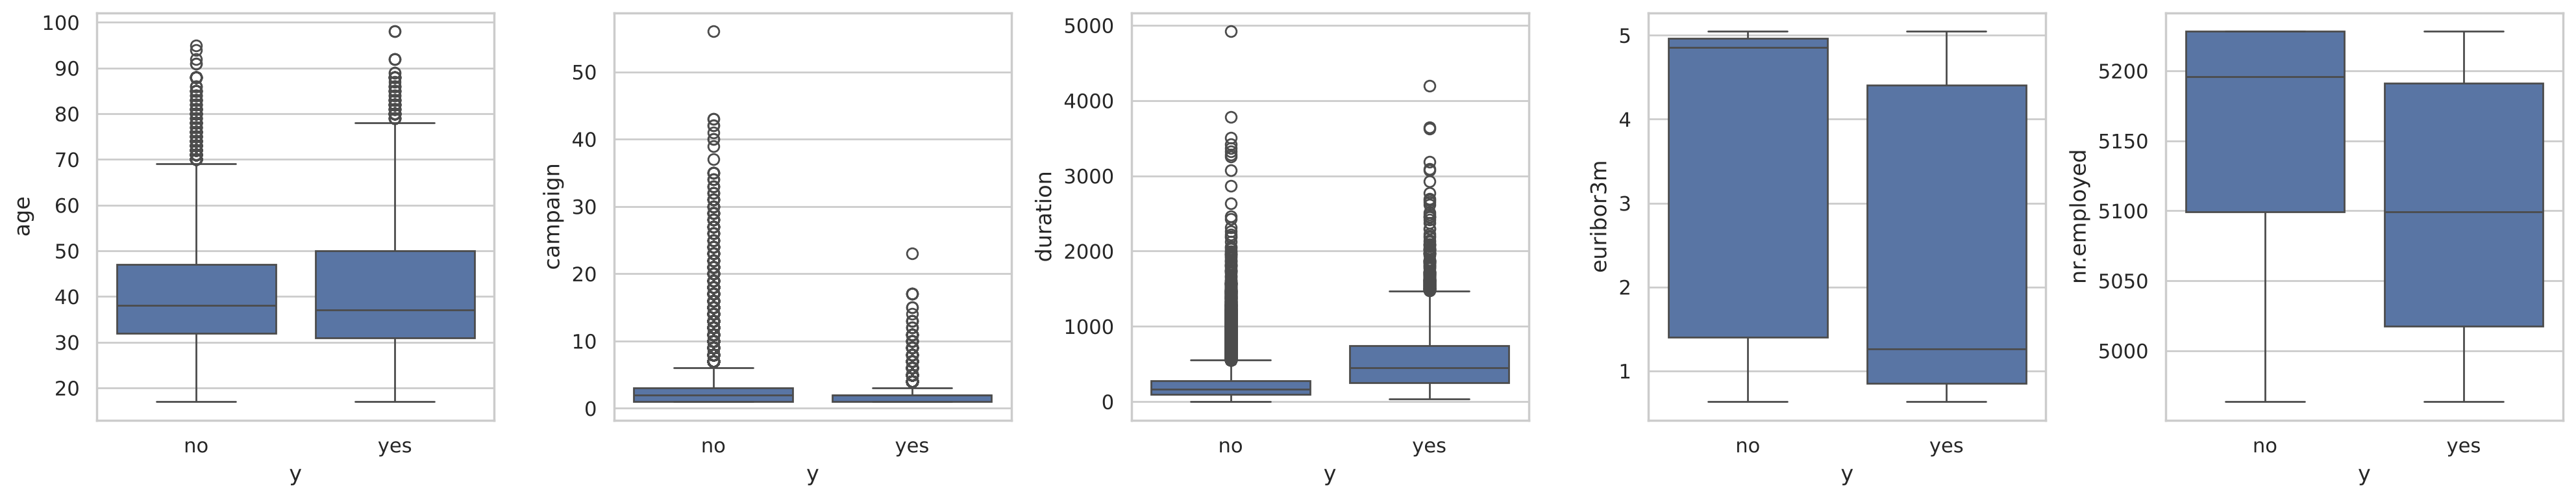

In [11]:
cols = ['age', 'campaign', 'duration', 'euribor3m', 'nr.employed']
fig, axes = plt.subplots(1, len(cols), figsize=(20, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(data=df, x='y', y=c, ax=ax)
plt.tight_layout()

**Question**: which attribute seems to separate `yes` and `no` best? Keep it in mind: we will come back to it immediately.

> **Answer.** `duration` separates the two classes far better than any other attribute; `euribor3m` and `nr.employed` also differ clearly (subscriptions are more frequent in periods with low interest rates and lower employment). Among the categorical attributes, `poutcome = success` has a subscription rate above 60%.

## 3. Data preparation

### 3.1 Duplicates
Remove the duplicated rows.

In [12]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(41176, 21)

### 3.2 Data leakage: the case of `duration`
Think about **when** each attribute is known.

**Question**: the bank wants to use the model to decide *whom to call*. Is `duration` available at that moment? What would happen if we kept it?

> **Answer.** `duration` is known only **after** the call has ended – and when it is 0 the outcome is certainly `no`. A model using it would look excellent on the test set but would be useless in production, where we must decide *before* calling. This is **data leakage**: information that would not be available at prediction time leaks into the training data. We drop `duration` (section 7 shows how much it would inflate the result).

In [13]:
df_leak = df.copy()                       # kept only for the optional section 7
df = df.drop(columns=['duration'])

### 3.3 The code 999 in `pdays`
For a decision tree the value 999 is not a big problem: a split such as `pdays <= 998` separates "previously contacted" from "never contacted". For other methods (e.g. *k*-nearest neighbours, Lab 4) 999 would be treated as a huge distance. We make the information explicit with a binary attribute `prev_contacted`.

In [14]:
df['prev_contacted'] = (df['pdays'] != 999).astype(int)
df['prev_contacted'].value_counts()

prev_contacted
0    39661
1     1515
Name: count, dtype: int64

### 3.4 Predictors and target
scikit-learn wants a matrix of predictors `X` and a vector `y`. Encode the target as `1` = `yes`, `0` = `no`.

In [15]:
y = (df['y'] == 'yes').astype(int)
X = df.drop(columns=['y'])
print(X.shape, y.mean().round(3))

(41176, 20) 0.113


### 3.5 Encoding the categorical attributes
scikit-learn trees accept only numbers. With **one-hot encoding** each categorical attribute with *k* values becomes *k* binary columns. Use [`pd.get_dummies`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html) with `dtype=int`.

*Note*: here encoding before the split is harmless, because it does not use statistics computed on the data. In Lab 2 we will do it the clean way, with `OneHotEncoder` inside a scikit-learn `Pipeline`.

In [16]:
X = pd.get_dummies(X, columns=cat_cols, dtype=int)
print(X.shape)
X.columns.tolist()[:25]

(41176, 63)


['age',
 'campaign',
 'pdays',
 'previous',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'prev_contacted',
 'job_admin.',
 'job_blue-collar',
 'job_entrepreneur',
 'job_housemaid',
 'job_management',
 'job_retired',
 'job_self-employed',
 'job_services',
 'job_student',
 'job_technician',
 'job_unemployed',
 'job_unknown',
 'marital_divorced',
 'marital_married',
 'marital_single']

## 4. Holdout and baseline

### 4.1 Train/test split
Split the data into 70% training and 30% test with [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html), using `stratify=y` and `random_state=RANDOM_STATE`. Check the rate of `yes` in the two parts.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print(f'rate of yes - train: {y_train.mean():.3f}  test: {y_test.mean():.3f}')

(28823, 63) (12353, 63)
rate of yes - train: 0.113  test: 0.113


**Question**: why `stratify=y`? What could happen without it, with a minority class this small?

> **Answer.** Stratification keeps the same class proportions in training and test. With ~11% positives, a purely random split may produce slightly different proportions, and the test score would partly depend on this luck; with very small datasets the minority class could almost disappear from one of the parts.

### 4.2 Baseline
A [`DummyClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html) with `strategy='most_frequent'` always predicts the majority class. Train it and compute its test accuracy: this is the number to beat.

In [18]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, dummy.predict(X_test))
print(f'Baseline test accuracy: {baseline_acc:.3f}')

Baseline test accuracy: 0.887


## 5. A first decision tree
Train a [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) with `max_depth=3`. Use `criterion='entropy'`, i.e. splits chosen by **information gain** as seen in class (the scikit-learn default is `'gini'`, which usually gives very similar trees).

Compute the accuracy on the **training** set and on the **test** set.

In [19]:
tree3 = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=RANDOM_STATE)
tree3.fit(X_train, y_train)

acc_train = accuracy_score(y_train, tree3.predict(X_train))
acc_test = accuracy_score(y_test, tree3.predict(X_test))
print(f'train accuracy: {acc_train:.4f}   test accuracy: {acc_test:.4f}   (baseline {baseline_acc:.4f})')

train accuracy: 0.8997   test accuracy: 0.8991   (baseline 0.8873)


### 5.1 Visualise the tree
Use [`plot_tree`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html) with the names of the features and of the classes. In each node: the split condition, the entropy, the number of training samples, the class distribution `value = [no, yes]` and the majority class.

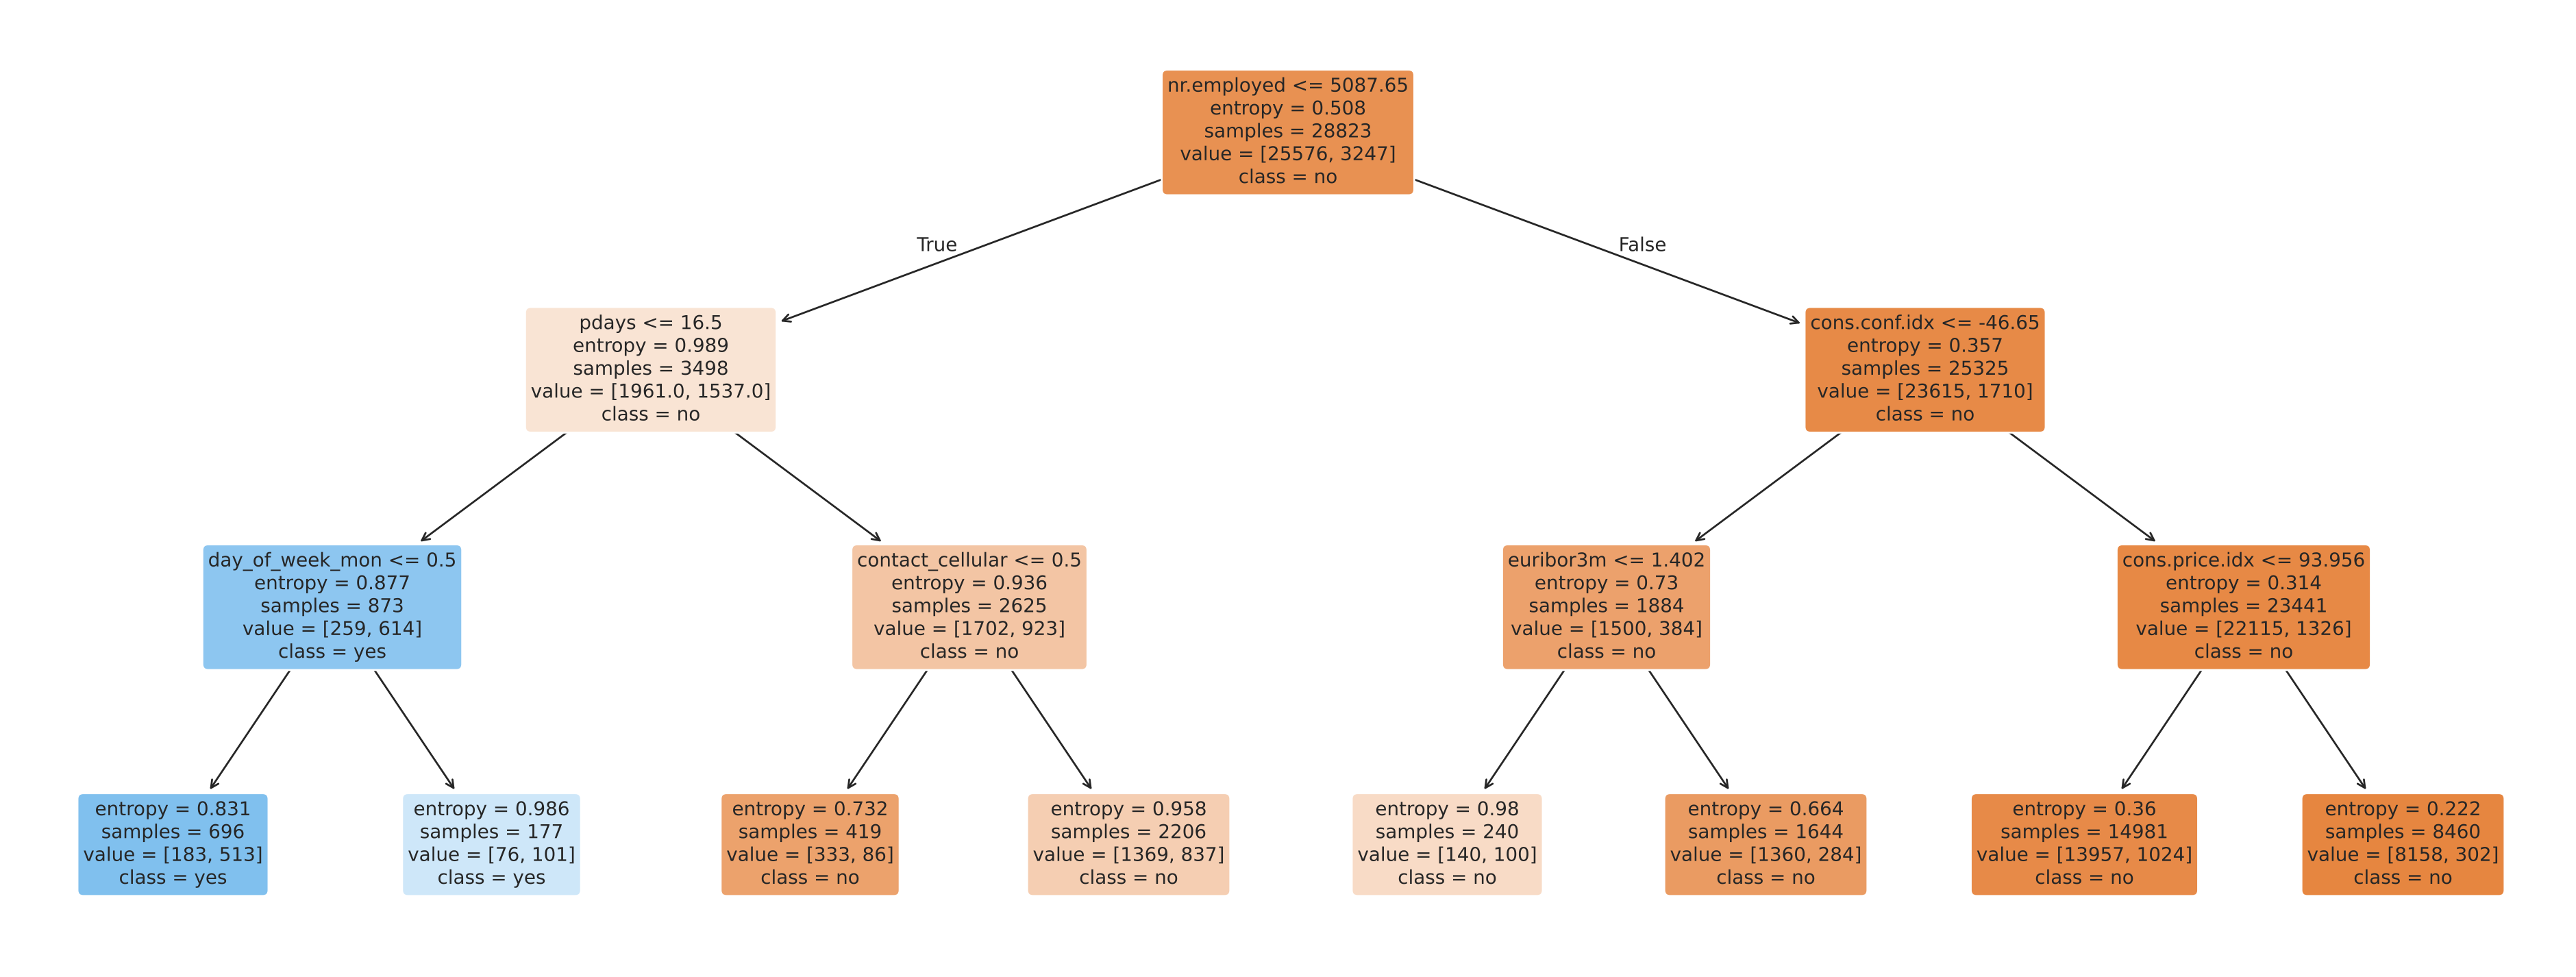

In [20]:
plt.figure(figsize=(24, 9))
plot_tree(tree3, feature_names=X.columns, class_names=['no', 'yes'],
          filled=True, rounded=True, fontsize=10)
plt.show()

The same tree as text, convenient to read the rules:

In [21]:
print(export_text(tree3, feature_names=list(X.columns), show_weights=True))

|--- nr.employed <= 5087.65
|   |--- pdays <= 16.50
|   |   |--- day_of_week_mon <= 0.50
|   |   |   |--- weights: [183.00, 513.00] class: 1
|   |   |--- day_of_week_mon >  0.50
|   |   |   |--- weights: [76.00, 101.00] class: 1
|   |--- pdays >  16.50
|   |   |--- contact_cellular <= 0.50
|   |   |   |--- weights: [333.00, 86.00] class: 0
|   |   |--- contact_cellular >  0.50
|   |   |   |--- weights: [1369.00, 837.00] class: 0
|--- nr.employed >  5087.65
|   |--- cons.conf.idx <= -46.65
|   |   |--- euribor3m <= 1.40
|   |   |   |--- weights: [140.00, 100.00] class: 0
|   |   |--- euribor3m >  1.40
|   |   |   |--- weights: [1360.00, 284.00] class: 0
|   |--- cons.conf.idx >  -46.65
|   |   |--- cons.price.idx <= 93.96
|   |   |   |--- weights: [13957.00, 1024.00] class: 0
|   |   |--- cons.price.idx >  93.96
|   |   |   |--- weights: [8158.00, 302.00] class: 0



**Questions**
1. Which attribute is used at the root? Why do you think it was chosen?
2. Find the leaf with the highest proportion of `yes`. Translate the path from the root into a business rule ("clients who … ").
3. How many leaves predict `yes`? Compare the test accuracy with the baseline: how much did we gain?

> **Answer.** See the comments right after the feature importances below.

### 5.2 Which attributes does the tree use?
`feature_importances_` measures how much each attribute contributes to the reduction of impurity in the tree.

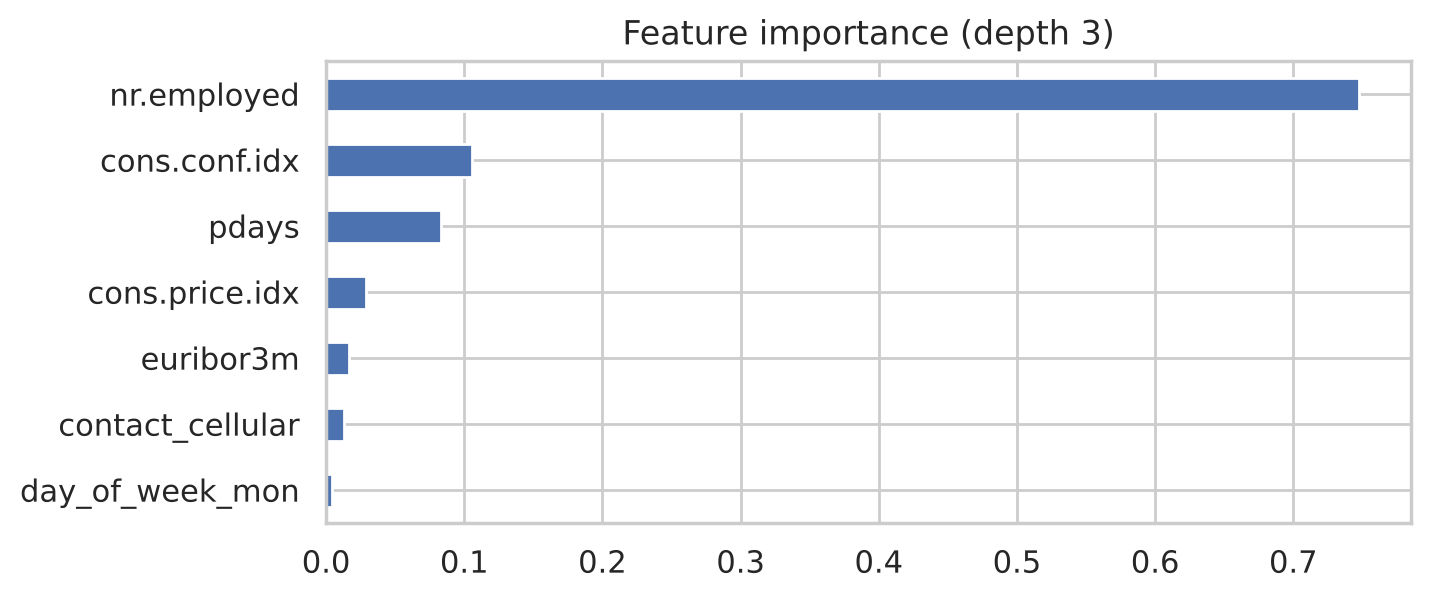

In [22]:
imp = pd.Series(tree3.feature_importances_, index=X.columns)
imp[imp > 0].sort_values().plot.barh(figsize=(7, 3), title='Feature importance (depth 3)');

> **Answers to the questions of section 5.**
> 1. The root splits on `nr.employed` (number of employees, a quarterly indicator) at about 5088: it is the single split with the highest information gain. Below the threshold the subscription rate is about 44%, above it about 7%. The tree is telling us that the **period** of the campaign (economic context, interest rates) matters more than any characteristic of the client.
> 2. The purest `yes` leaf (≈ 74% of `yes`, about 700 training contacts): *calls made in a period with low employment, to clients already contacted in a previous campaign (`pdays <= 16`), not on Monday*. Note that `pdays <= 16.5` is in practice the same as `prev_contacted = 1`.
> 3. Only 2 of the 8 leaves predict `yes`. Test accuracy ≈ 0.899 vs a baseline of ≈ 0.887: a gain of about one percentage point. The tree correctly identifies fewer than 1 subscriber out of 5 – accuracy hides this (Lab 3).
>
> Observe also that `feature_importances_` concentrates almost all the weight on 1–2 attributes: importance depends on the specific tree, not only on the data.

## 6. Overfitting

### 6.1 A fully grown tree
Train a tree **without** limits on the depth. How deep is it? How many leaves (`get_depth()`, `get_n_leaves()`)? Compare training and test accuracy.

In [23]:
full_tree = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE)
full_tree.fit(X_train, y_train)
print('depth:', full_tree.get_depth(), '  leaves:', full_tree.get_n_leaves())
print(f'train accuracy: {accuracy_score(y_train, full_tree.predict(X_train)):.4f}')
print(f'test accuracy:  {accuracy_score(y_test, full_tree.predict(X_test)):.4f}')

depth: 43   leaves: 4264
train accuracy: 0.9962
test accuracy:  0.8410


### 6.2 Accuracy as a function of the depth
For `max_depth` from 1 to 30, train a tree and store training and test accuracy; then plot the two curves together with the baseline.

best test accuracy 0.9017 at max_depth = 5


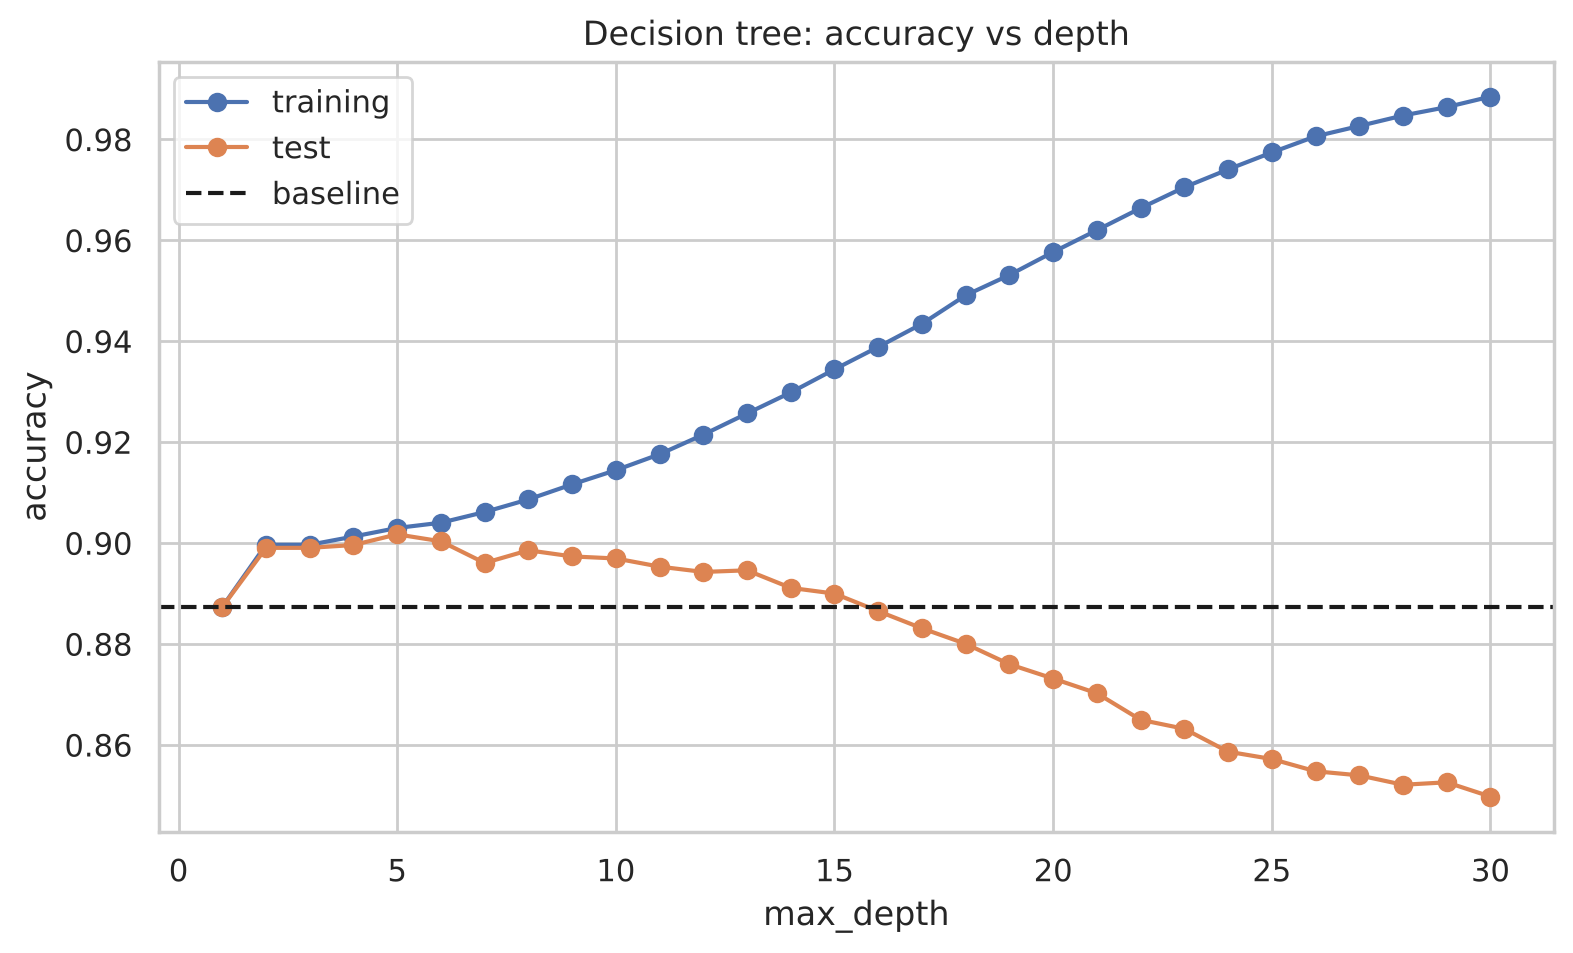

In [24]:
depths = range(1, 31)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, criterion='entropy', random_state=RANDOM_STATE)
    t.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, t.predict(X_train)))
    test_acc.append(accuracy_score(y_test, t.predict(X_test)))

plt.figure(figsize=(9, 5))
plt.plot(depths, train_acc, marker='o', label='training')
plt.plot(depths, test_acc, marker='o', label='test')
plt.axhline(baseline_acc, ls='--', c='k', label='baseline')
plt.xlabel('max_depth'); plt.ylabel('accuracy'); plt.legend()
plt.title('Decision tree: accuracy vs depth');

best_d = depths[int(np.argmax(test_acc))]
print(f'best test accuracy {max(test_acc):.4f} at max_depth = {best_d}')

**Questions**
1. Why does the training accuracy keep growing towards 1?
2. Where is the test accuracy highest? What happens beyond that point, and why?
3. We have just chosen the "best" depth by looking at the **test** set. Is the corresponding test accuracy a fair estimate of the performance on new clients?

> **Answers.** The fully grown tree has depth 43 and more than 4,000 leaves for about 29,000 training rows: it practically memorises the training set (train accuracy ≈ 0.996) and its test accuracy falls to ≈ 0.84, **below the baseline**.
> 1. A deeper tree can isolate smaller and smaller groups of training rows, down to single examples: training accuracy tends to 1 (it does not reach it exactly only because of identical rows with different labels).
> 2. The test accuracy peaks at a small depth (around 5, ≈ 0.90) and then decreases: the additional splits fit noise and peculiarities of the training sample that do not generalise – **overfitting**.
> 3. No: the depth was selected using the test set, which therefore is no longer independent of the model. The value is optimistic – a subtle form of leakage. The correct procedure (validation set or cross-validation on the training set) is the topic of Lab 2.

### 6.3 Exercise: limiting the size of the leaves
Overfitting can also be controlled with `min_samples_leaf` (minimum number of training samples in a leaf). Repeat the experiment of 6.2 without limiting the depth, for `min_samples_leaf` in `[1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]`. Use a logarithmic *x* axis (`plt.xscale('log')`). Which value works best? How large is the tree (number of leaves) at that value?

,min_samples_leaf,leaves,train,test
0,1,4264,0.9962,0.8410
1,2,3507,0.9598,0.8625
2,5,2157,0.9286,0.8788
3,10,1400,0.9163,0.8911
4,20,865,0.9090,0.8941
5,50,409,0.9038,0.8982
6,100,213,0.9016,0.9013
7,200,108,0.9010,0.9014
8,500,42,0.8997,0.8991
9,1000,19,0.8890,0.8906


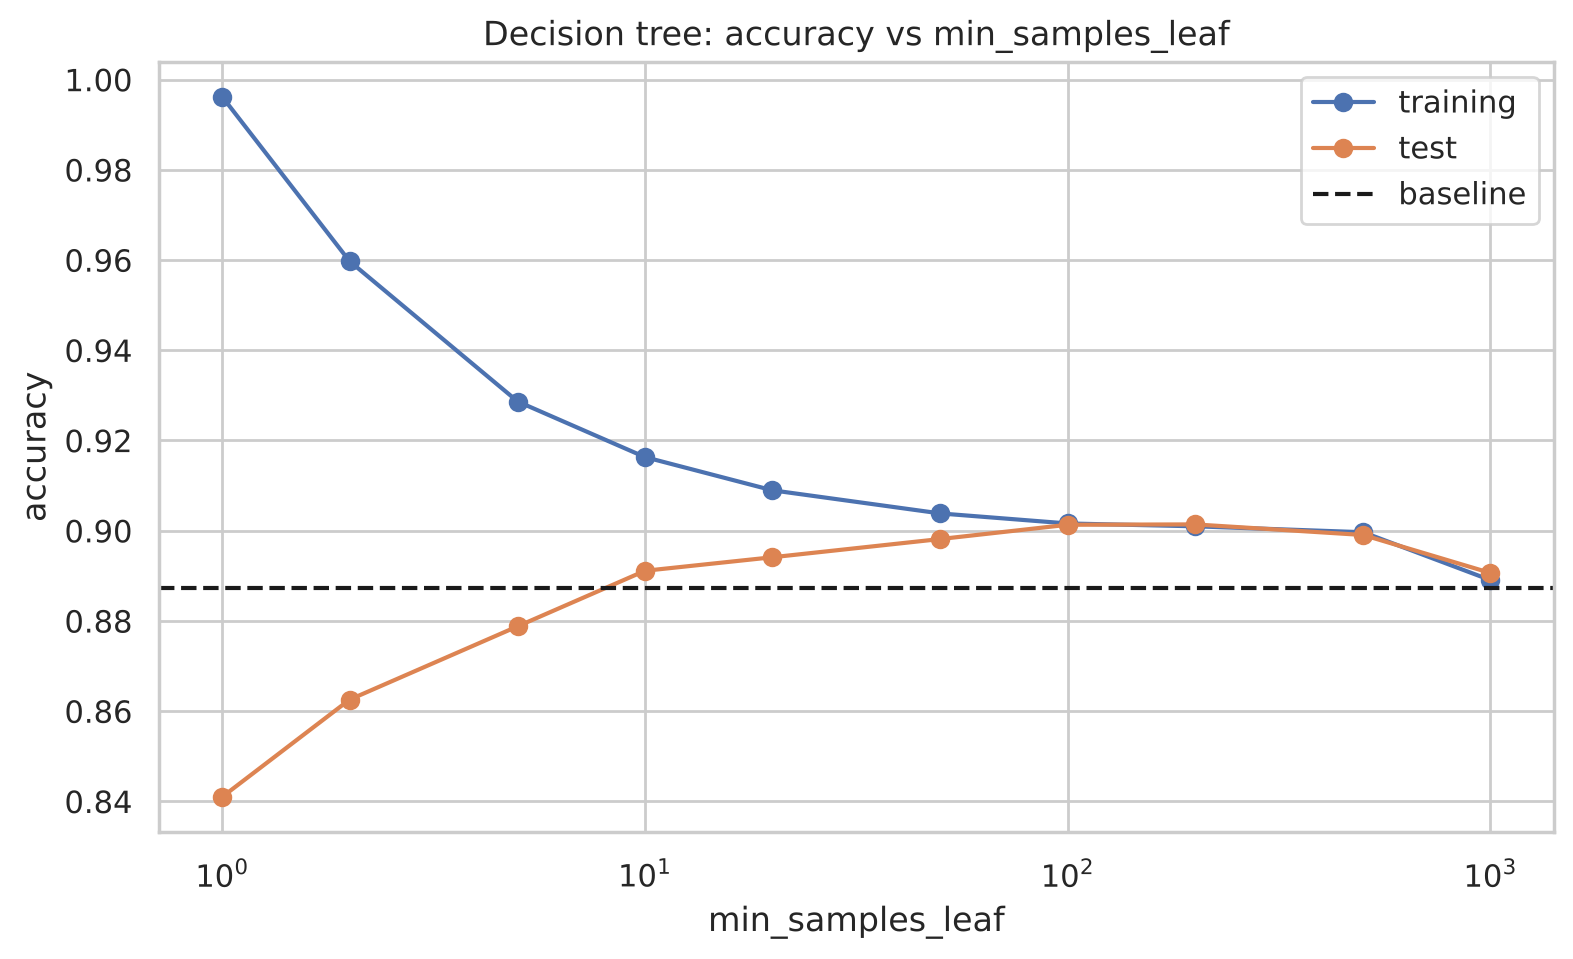

In [25]:
leaf_sizes = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
train_acc_l, test_acc_l, n_leaves = [], [], []
for m in leaf_sizes:
    t = DecisionTreeClassifier(min_samples_leaf=m, criterion='entropy', random_state=RANDOM_STATE)
    t.fit(X_train, y_train)
    train_acc_l.append(accuracy_score(y_train, t.predict(X_train)))
    test_acc_l.append(accuracy_score(y_test, t.predict(X_test)))
    n_leaves.append(t.get_n_leaves())

plt.figure(figsize=(9, 5))
plt.plot(leaf_sizes, train_acc_l, marker='o', label='training')
plt.plot(leaf_sizes, test_acc_l, marker='o', label='test')
plt.axhline(baseline_acc, ls='--', c='k', label='baseline')
plt.xscale('log'); plt.xlabel('min_samples_leaf'); plt.ylabel('accuracy'); plt.legend()
plt.title('Decision tree: accuracy vs min_samples_leaf');

pd.DataFrame({'min_samples_leaf': leaf_sizes, 'leaves': n_leaves,
              'train': np.round(train_acc_l, 4), 'test': np.round(test_acc_l, 4)})

> **Answer.** Very small leaves overfit (1 sample per leaf = the fully grown tree). The test accuracy is highest for `min_samples_leaf` between about 100 and 200 (≈ 0.901), with a tree of 100–200 leaves; with 500–1000 the tree becomes too simple and the accuracy decreases again (**underfitting**). Depth and leaf size are two different ways to control the **complexity** of the model.

## 7. Optional: what if we had kept `duration`?
Repeat the preparation on `df_leak` (which still contains `duration`), using **the same rows** for training and test, and train a tree of depth 5 with and without `duration`. Compare the test accuracies and also the **share of the real subscribers that each model identifies** (among the test clients with `y = 1`, the fraction predicted as `1`).

In [26]:
df_leak['prev_contacted'] = (df_leak['pdays'] != 999).astype(int)
X_leak = pd.get_dummies(df_leak.drop(columns=['y']), columns=cat_cols, dtype=int)

# same split as before, selected through the row index
X_leak_train, X_leak_test = X_leak.loc[X_train.index], X_leak.loc[X_test.index]

for name, (Xtr, Xte) in {'without duration': (X_train, X_test),
                         'with duration': (X_leak_train, X_leak_test)}.items():
    t = DecisionTreeClassifier(max_depth=5, criterion='entropy', random_state=RANDOM_STATE)
    t.fit(Xtr, y_train)
    pred = t.predict(Xte)
    found = pred[y_test == 1].mean()      # share of the real subscribers that the model identifies
    print(f'{name:17s} test accuracy: {accuracy_score(y_test, pred):.4f}   subscribers identified: {found:.1%}')

without duration  test accuracy: 0.9017   subscribers identified: 25.4%
with duration     test accuracy: 0.9127   subscribers identified: 50.9%


**Question**: the model with `duration` is clearly "better". Why would it be a serious mistake to deliver it to the bank?

> **Answer.** With `duration` the accuracy grows by only about one point, but the share of subscribers identified roughly doubles (≈ 25% → ≈ 51%): accuracy hides the effect because of the imbalance. Yet the model is useless, because at prediction time – before the call – `duration` does not exist yet. The higher score measures the ability to recognise a call that *has already gone well*, not to choose whom to call. Leakage produces models that look excellent in the lab and fail in production; the only defence is to ask, for every attribute, *when is it known?*

## 8. Wrap-up
Discuss with your neighbour and write two lines for each question:
1. The best tree gains only a little accuracy over the baseline. Does this mean it is useless for the bank? What would you rather measure? → *Lab 3: performance measures*
2. We chose `max_depth` looking at the test set. How should we choose it, keeping the test set apart? → *Lab 2: validation and cross-validation*
3. Change `RANDOM_STATE` and re-run sections 4–6. Does the best depth change? What does this say about a single holdout split? → *Lab 2*

> **Answer.** 1. Not necessarily: the tree identifies groups of clients with a subscription rate well above 11% (e.g. those reached in periods of low `nr.employed`, or successful in the previous campaign). For the bank, what matters is *how many subscribers we find for a given number of calls* – recall, precision, lift (Lab 3) – and the cost of a call vs the value of a deposit.
2. With a separate **validation** set or, better, with **cross-validation** on the training set only (`GridSearchCV`); the test set is used once, at the end.
3. Typically the best depth and the corresponding accuracy change with the seed: a single holdout gives a **noisy** estimate, another reason for cross-validation.